# Replicate correlation of the bulk profiles

Measures how well the replicate wells of each cell line agree, with the pairwise Pearson correlation between their bulk profiles.

**Why:** if the replicate wells of a cell line are similar, a profile reflects the cell line and not noise in one well.
A shuffled-feature baseline shows what a correlation of unrelated profiles looks like.

**Input:** `<plate>_bulk_feature_selected.parquet` of each plate (multivariate: the features selected for that plate).
Each plate has its own features, so correlations are computed within a plate.

**Extreme features** are removed first: a feature with an absolute value above `outlier_cutoff` in any well of the plate.
Some features have a near-zero MAD on a plate, so normalization gives values up to about 1e19, and one such feature would decide the correlation of two profiles on its own.
The pooled bulk profiles (`4.preprocess_features/3b.pooled_bulk_processing.ipynb`) remove the same features with the same cutoff.

**Replicates** are the wells of one plate with the same cell line, seeding density, and plate coating.
Most cell lines have four replicate wells, which gives six pairs.
The four wells of a cell line are neighbors on the plate (a 2x2 block), so they also share their position.

**Method:** the correlations come from the lab's [`pairwise_compare`](https://github.com/WayScience/pairwise_compare) package (`compare_pairs`, which gives the Pearson correlation by default), as in the PedCP90 optimization (`pediatric_cancer_atlas_profiling/4.optimization`).
It gives the same Pearson correlation as `numpy.corrcoef` (checked on the pooled bulk profiles: all 1,068 pairs of replicate wells, largest difference 2e-15).
The package (`pairwise-compare` on PyPI) is installed by the `environments/preprocessing` uv environment.

**Shuffled baseline:** as in the PedCP90 optimization, a shuffled copy of the plate is made by shuffling the values of each feature among the wells of the plate (fixed seed).
The replicate pairs of the shuffled copy are compared the same way. Their correlation is the chance level for the plate: low, but not exactly zero, because every feature keeps its distribution (shuffling the order of the features within each well instead, `axis=1` in `rng.permuted`, gives a baseline of exactly zero on average).

**Output:** in `results/1.replicate_correlation/`
- `replicate_well_pair_correlations.csv`: one row per pair of replicate wells, for the real plate (`shuffled` is False) and for the shuffled copy (`shuffled` is True). Columns: plate, time point, cell line, seeding density, plate coating, the two wells, `shuffled`, `pearson`, `n_features`, and the cancer group and tissue site of the cell line.
- `replicate_correlation_per_cell_line_and_plate.csv`: one row per cell line and plate with the mean correlation over its pairs (`pearson`) and the mean of the shuffled baseline (`shuffled_pearson`).

The notebook also plots the correlations (a histogram against the baseline, and the mean correlation of each cell line); the plot is shown in the notebook and is not saved to disk.

## Import libraries

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from pairwise_compare import compare_pairs
from pccma_utils.cell_lines import load_cell_line_groups
from pccma_utils.palettes import site_colors

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# per-plate bulk feature-selected profiles: use the local data folder and fall back to the bandicoot mount
local_dir = pathlib.Path("../4.preprocess_features/data/bulk_profiles")
bandicoot_dir = pathlib.Path("~/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles/bulk_profiles").expanduser()
profile_dir = local_dir if any(local_dir.glob("BR*_bulk_feature_selected.parquet")) else bandicoot_dir

results_dir = pathlib.Path("./results/1.replicate_correlation")
results_dir.mkdir(parents=True, exist_ok=True)

# wells with the same values of these columns (within a plate) are replicates
# (the pairs are saved sorted by these columns in this order, which is the alphabetical order of their names)
replicate_columns = ["Metadata_Plate", "Metadata_cell_line", "Metadata_plate_coating", "Metadata_seeding_density", "Metadata_time_point"]
outlier_cutoff = 1000  # features above this absolute value in any well are removed (near-zero MAD artifacts)
rng = np.random.default_rng(0)  # for the shuffled copy of each plate

## Correlation between replicate wells

One plate at a time.

In [3]:
pair_tables = []
n_features = {}
for plate_file in sorted(profile_dir.glob("BR*_bulk_feature_selected.parquet")):
    plate_df = pd.read_parquet(plate_file)
    plate = plate_df["Metadata_Plate"].iloc[0]
    features = [col for col in plate_df.columns if not col.startswith("Metadata_")]
    extreme = [col for col in features if plate_df[col].abs().max() > outlier_cutoff]
    features = [col for col in features if col not in extreme]
    n_features[plate] = len(features)
    print(f"{plate}: {len(features)} features ({len(extreme)} removed for values above {outlier_cutoff})")

    # shuffled copy of the plate: the values of every feature are shuffled among the wells
    plate_df = plate_df[replicate_columns + ["Metadata_Well"] + features]
    shuffled_df = plate_df.copy()
    shuffled_df[features] = rng.permuted(plate_df[features].to_numpy(), axis=0)
    both_df = pd.concat([plate_df.assign(Shuffled=False), shuffled_df.assign(Shuffled=True)], ignore_index=True)

    # Pearson correlation of every pair of wells with the same values of the replicate columns (and the same Shuffled)
    pair_tables.append(
        compare_pairs(both_df, different=["Metadata_Well"], features=features, same=replicate_columns + ["Shuffled"])
    )

# pairwise_compare names the columns of the two compared wells <column>__group0 and <column>__group1; both wells have the same replicate columns
pairs_df = pd.concat(pair_tables, ignore_index=True).rename(columns={
    **{f"{col}__group0": col.replace("Metadata_", "") for col in replicate_columns + ["Shuffled"]},
    "Metadata_Well__group0": "well_a",
    "Metadata_Well__group1": "well_b",
    "pearsons_correlation": "pearson",
})
pairs_df = pairs_df.rename(columns={"Plate": "plate", "Shuffled": "shuffled"})
pairs_df = pairs_df[["plate", "time_point", "cell_line", "seeding_density", "plate_coating", "well_a", "well_b", "shuffled", "pearson"]]
pairs_df["n_features"] = pairs_df["plate"].map(n_features)

cell_line_groups = load_cell_line_groups(metadata_path, groups_path).set_index("cell_line")
pairs_df["cancer_group"] = pairs_df["cell_line"].map(cell_line_groups["cancer_group"])
pairs_df["tissue_site"] = pairs_df["cell_line"].map(cell_line_groups["tissue_site"])
assert pairs_df["cancer_group"].notna().all(), "a cell line has no cancer group"

pairs_df.to_csv(results_dir / "replicate_well_pair_correlations.csv", index=False)
real_pairs = pairs_df[~pairs_df["shuffled"]]
print(f"{len(real_pairs)} pairs of replicate wells from {real_pairs['plate'].nunique()} plates and {real_pairs['cell_line'].nunique()} cell lines")

BR00150695: 322 features (1 removed for values above 1000)


BR00150696: 337 features (1 removed for values above 1000)


BR00150697: 339 features (1 removed for values above 1000)


BR00150698: 381 features (1 removed for values above 1000)


BR00150699: 386 features (1 removed for values above 1000)


BR00150700: 372 features (1 removed for values above 1000)


BR00150701: 309 features (0 removed for values above 1000)


BR00150702: 292 features (0 removed for values above 1000)


BR00150703: 263 features (0 removed for values above 1000)


1068 pairs of replicate wells from 9 plates and 54 cell lines


## Summary per cell line and plate

In [4]:
group_columns = ["cell_line", "plate", "time_point", "seeding_density", "plate_coating", "cancer_group", "tissue_site"]
observed = pairs_df[~pairs_df["shuffled"]].groupby(group_columns).agg(n_pairs=("pearson", "size"), pearson=("pearson", "mean"))
baseline = pairs_df[pairs_df["shuffled"]].groupby(group_columns)["pearson"].mean().rename("shuffled_pearson")
summary_df = observed.join(baseline).reset_index()
summary_df.to_csv(results_dir / "replicate_correlation_per_cell_line_and_plate.csv", index=False)

print("Mean replicate correlation per cell line, by time point (median over cell lines, and range):")
print(summary_df.groupby("time_point")["pearson"].agg(["median", "min", "max"]).round(2).to_string())
print(f"\nShuffled baseline: median {summary_df['shuffled_pearson'].median():.3f}, largest {summary_df['shuffled_pearson'].abs().max():.3f}")
print(f"Pairs with a correlation above 0.5: {(real_pairs['pearson'] > 0.5).mean():.1%}")

lowest = summary_df.nsmallest(5, "pearson")[["cell_line", "time_point", "pearson"]]
print("\nLowest replicate correlations:")
print(lowest.round(2).to_string(index=False))

Mean replicate correlation per cell line, by time point (median over cell lines, and range):
            median   min   max
time_point                    
24            0.87  0.52  0.99
48            0.86  0.44  0.99
72            0.87  0.31  0.98

Shuffled baseline: median 0.044, largest 0.287
Pairs with a correlation above 0.5: 96.4%

Lowest replicate correlations:
cell_line  time_point  pearson
  CHLA194          72     0.31
  CHLA196          48     0.44
  CHLA210          24     0.52
    U2-OS          24     0.58
  CHLA186          48     0.59


## Replicate correlation at a glance

Left, the correlation of all pairs of replicate wells against the shuffled copy of the plate.
Right, the mean correlation of each cell line (dot) and its range over the plates (line), colored by tissue site.
The cell lines with the lowest replicate correlation are on top.
The plot is displayed here and not saved to disk.

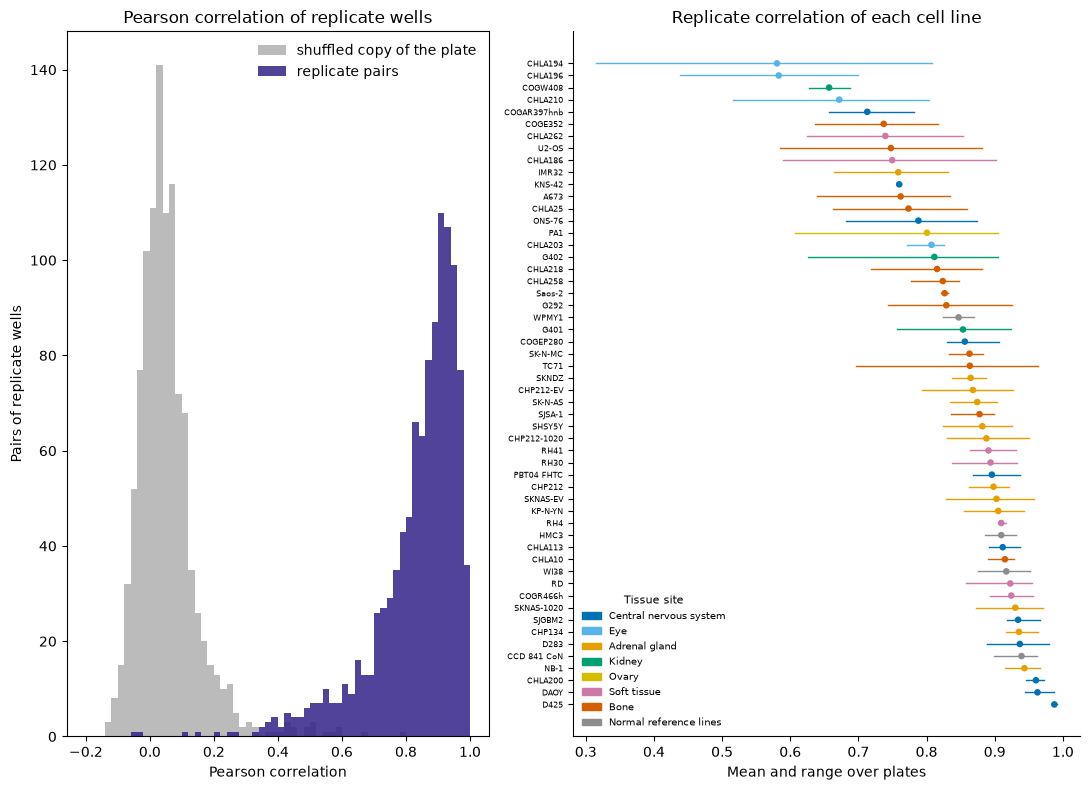

In [5]:
fig, (hist_ax, line_ax) = plt.subplots(1, 2, figsize=(11, 8), gridspec_kw={"width_ratios": [1, 1.2]})

bins = np.linspace(-0.2, 1, 61)
hist_ax.hist(pairs_df.loc[pairs_df["shuffled"], "pearson"], bins=bins, color="#BBBBBB", label="shuffled copy of the plate")
hist_ax.hist(pairs_df.loc[~pairs_df["shuffled"], "pearson"], bins=bins, color="#332288", alpha=0.85, label="replicate pairs")
hist_ax.set(title="Pearson correlation of replicate wells", xlabel="Pearson correlation", ylabel="Pairs of replicate wells")
hist_ax.legend(frameon=False)

per_line = (
    summary_df.groupby(["cell_line", "tissue_site"])["pearson"].agg(mean="mean", low="min", high="max").reset_index()
    .sort_values("mean").reset_index(drop=True)
)
for row in per_line.itertuples():
    line_ax.plot([row.low, row.high], [row.Index, row.Index], color=site_colors[row.tissue_site], lw=1)
line_ax.scatter(per_line["mean"], per_line.index, c=per_line["tissue_site"].map(site_colors), s=14, zorder=3)
line_ax.set_yticks(per_line.index, per_line["cell_line"], fontsize=6)
line_ax.invert_yaxis()
line_ax.set(title="Replicate correlation of each cell line", xlabel="Mean and range over plates")
line_ax.spines[["top", "right"]].set_visible(False)
line_ax.legend(
    handles=[Patch(color=color, label=site) for site, color in site_colors.items() if site in set(per_line["tissue_site"])],
    title="Tissue site", fontsize=7, title_fontsize=8, frameon=False, loc="lower left",
)
fig.tight_layout()
plt.show()